# Bivariate analysis

How each feature relates to `heartdisease`, and how the features relate to each other.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.linear_model import LinearRegression

import helpers
from helpers import CAT_COLS, NUM_COLS

helpers.setup()

In [2]:
data = helpers.load_data()

## Numerical variables against each other

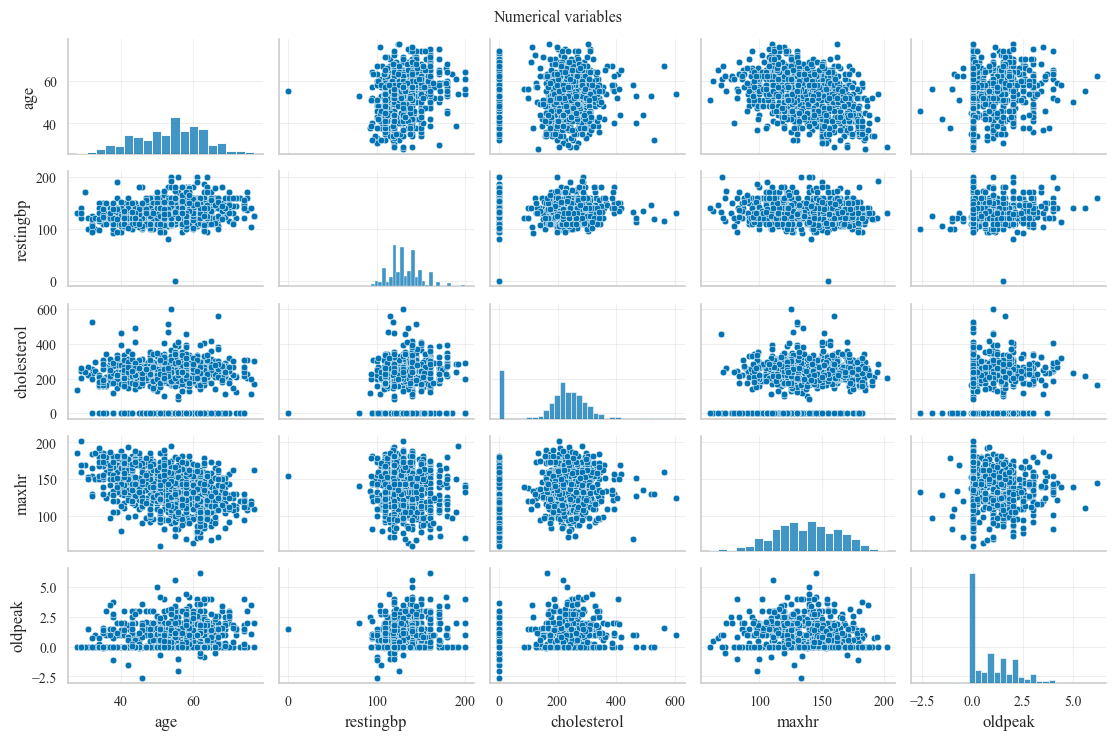

In [3]:
sns.pairplot(data[NUM_COLS], height=1.5, aspect=1.5)
plt.suptitle('Numerical variables')
plt.tight_layout()
plt.show()

## Categorical variables against the target

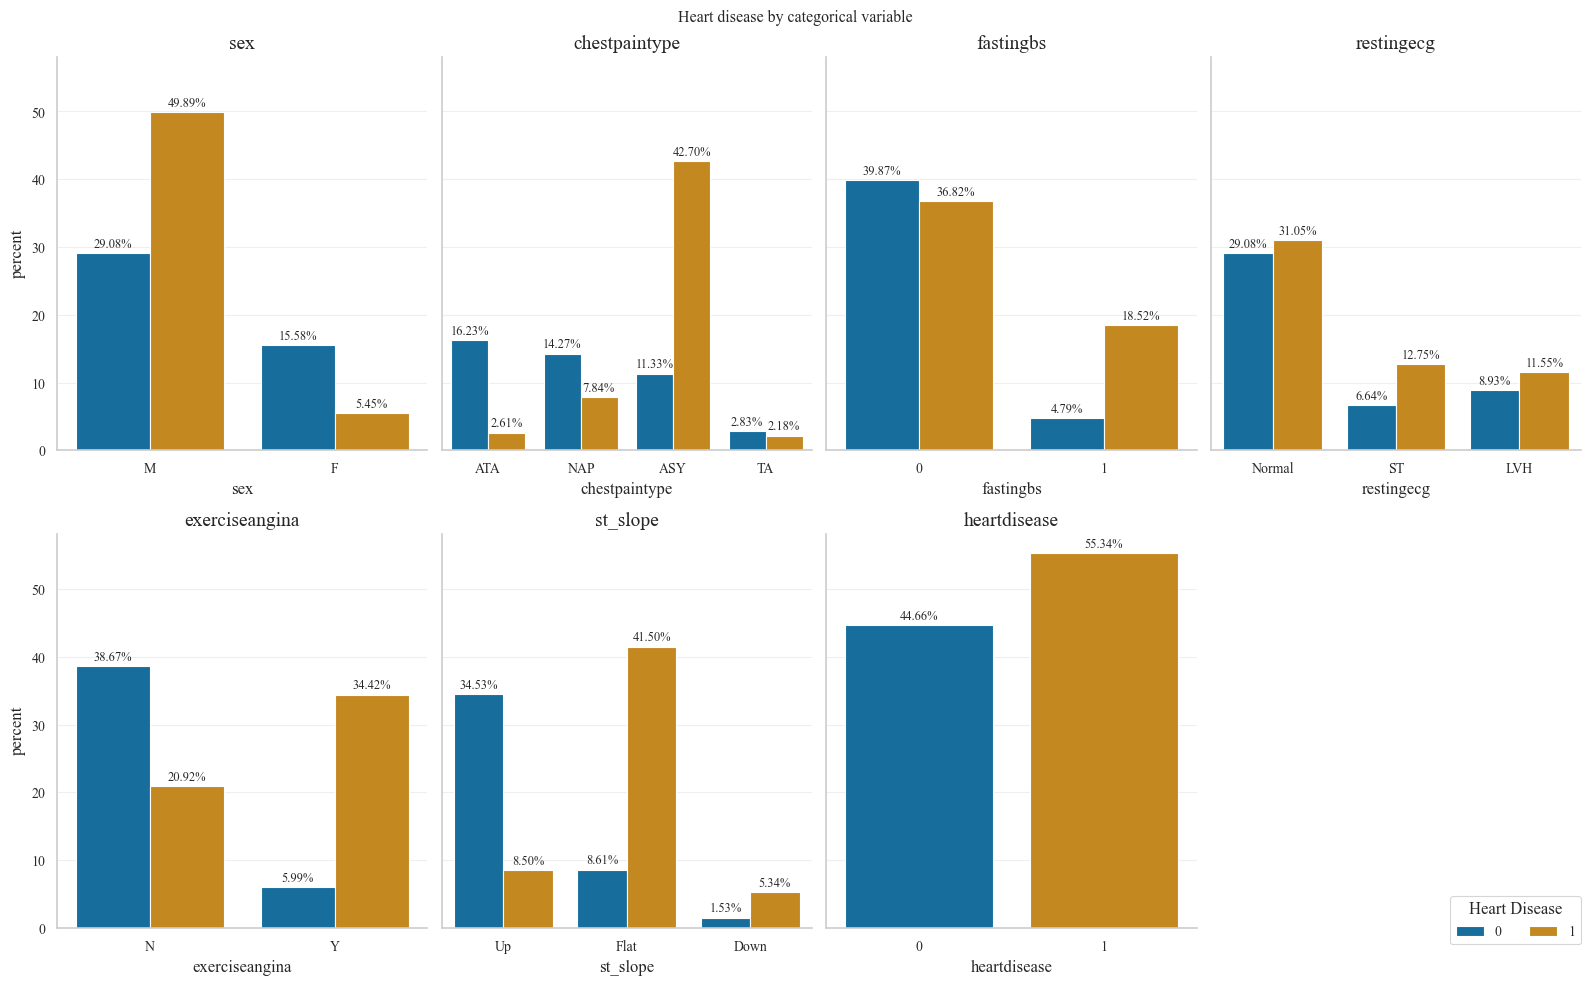

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 10), sharey=True)
axes = axes.flatten()
fig.suptitle('Heart disease by categorical variable')

for ax, col in zip(axes, CAT_COLS):
    sns.countplot(data=data, x=col, hue='heartdisease', stat='percent', ax=ax)
    ax.set_title(col)

    for bar in ax.patches:
        if bar.get_height() > 0:
            ax.annotate(f'{bar.get_height():.2f}%',
                        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha='center', va='bottom', fontsize=9,
                        xytext=(0, 2), textcoords='offset points')

# One shared legend instead of eight identical ones.
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    if ax.get_legend():
        ax.get_legend().remove()
fig.legend(handles, labels, title='Heart Disease', loc='upper center',
           ncol=2, bbox_to_anchor=(0.95, 0.1))

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

Population of female in this dataset is less, female with heart disease is even less

Categories that have hight percentage of heart disease:

- Exerciseangina = Y
- Flat st_slope
- ASY chestpaintype
- Male
- Normal RestingECG

## Age, sex and the target

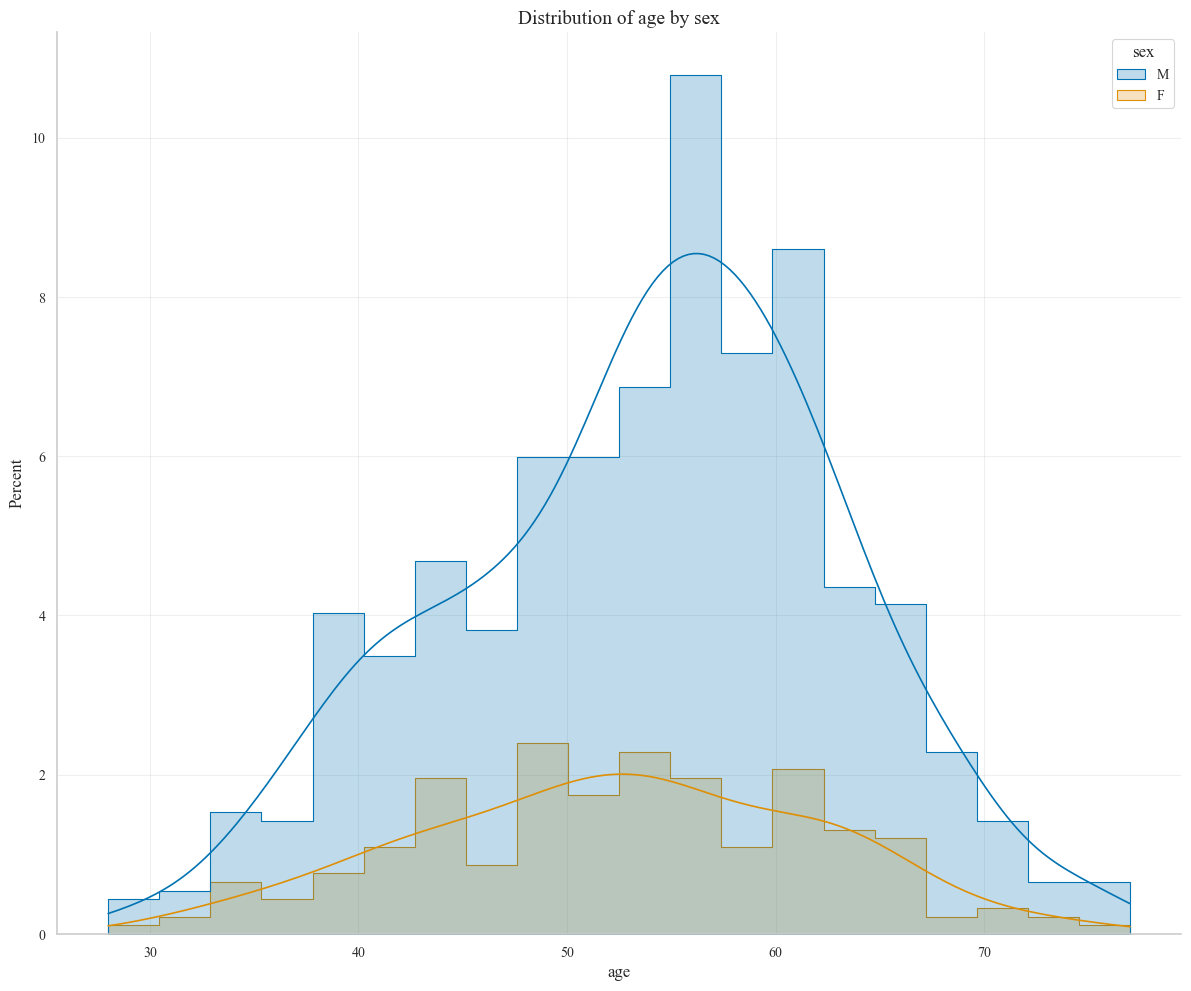

In [5]:
sns.histplot(data=data, x='age', bins=20, hue='sex', element='step',
             kde=True, stat='percent')
plt.title('Distribution of age by sex')
plt.tight_layout()
plt.show()

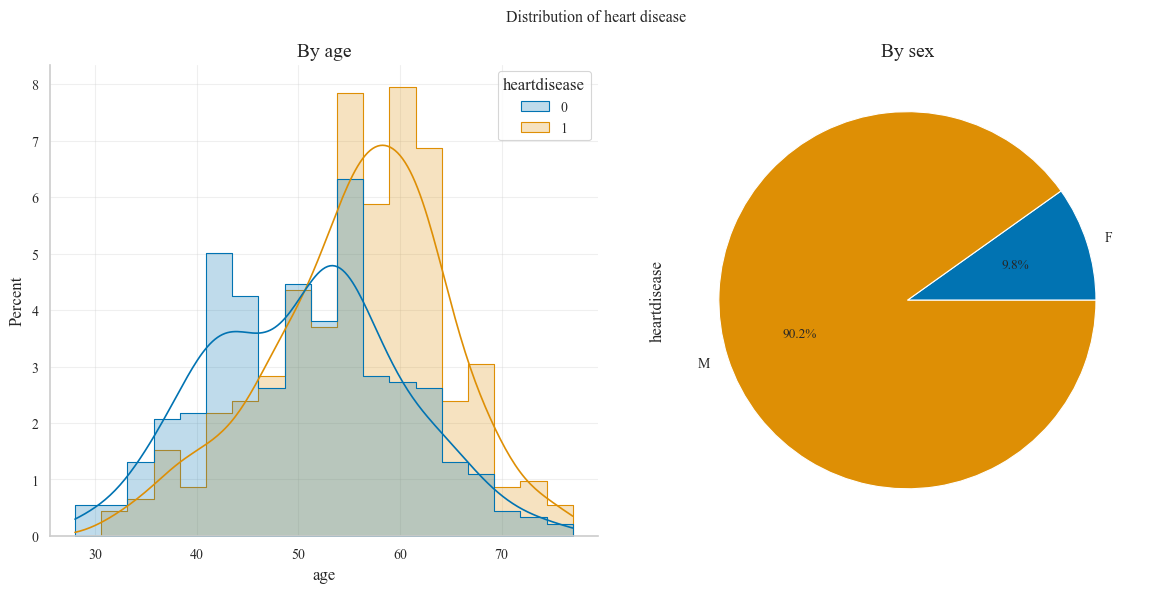

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Distribution of heart disease')

sns.histplot(data=data, x='age', hue='heartdisease', element='step',
             kde=True, stat='percent', ax=axes[0])
axes[0].set_title('By age')

data.groupby('sex')['heartdisease'].sum().plot(kind='pie', autopct='%1.1f%%', ax=axes[1])
axes[1].set_title('By sex')

plt.tight_layout()
plt.show()

Heart disease tends to increase by age, right-skewed, and more prevalent in male

## Numerical variables against the target

In [7]:
data[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
restingbp,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
maxhr,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2


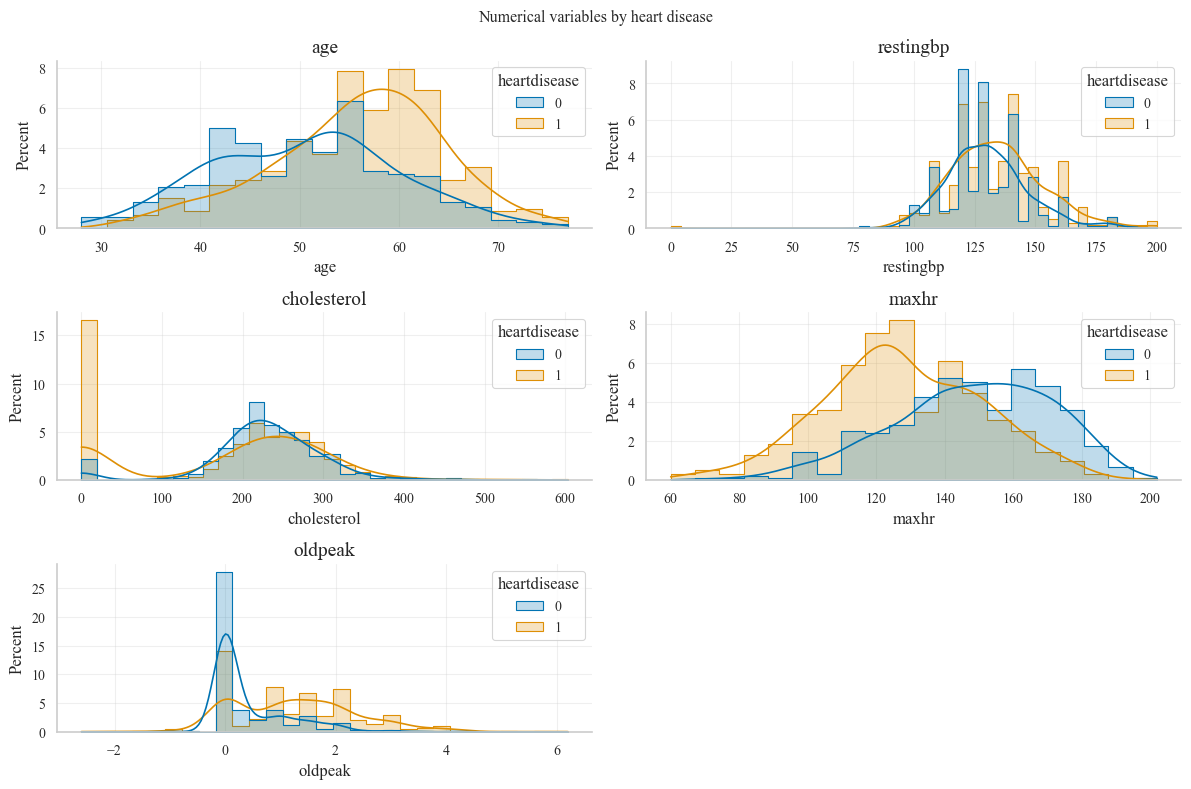

In [8]:
def plot_numeric_by_target(df, title):
    fig, axes = plt.subplots(3, 2, figsize=(12, 8))
    axes = axes.flatten()
    fig.suptitle(title)

    for ax, col in zip(axes, NUM_COLS):
        sns.histplot(data=df, x=col, hue='heartdisease', kde=True,
                     element='step', stat='percent', common_norm=True, ax=ax)
        ax.set_title(col)

    axes[-1].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_numeric_by_target(data, 'Numerical variables by heart disease')

Heart disease tends to increase by age, in people with high resting blood pressure, and in people with oldpeak > 0, an low maxhr??

### Same plot after treating the placeholder zeros as missing

In [9]:
df_clean = helpers.load_data(zeros_as_missing=True)
df_clean[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
restingbp,917.0,132.540894,17.999749,80.0,120.00,130.0,140.0,200.0
cholesterol,746.0,244.635389,59.153524,85.0,207.25,237.0,275.0,603.0
maxhr,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2


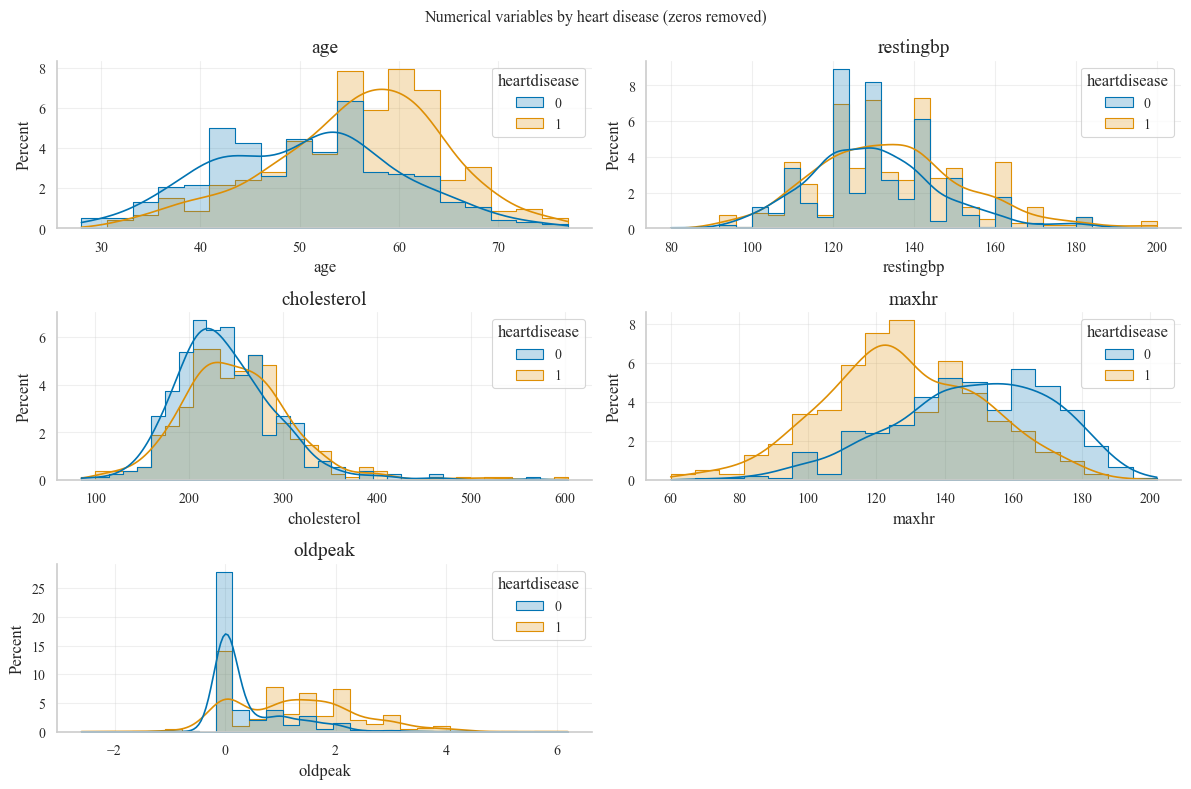

In [10]:
plot_numeric_by_target(df_clean, 'Numerical variables by heart disease (zeros removed)')

## Correlation

In [11]:
data[NUM_COLS].cov()

,age,restingbp,cholesterol,maxhr,oldpeak
age,88.974254,44.427519,-98.309701,-91.750920,2.601774
restingbp,44.427519,342.773903,204.323837,-52.857808,3.254307
cholesterol,-98.309701,204.323837,11964.891079,656.671673,5.850572
maxhr,-91.750920,-52.857808,656.671673,648.228614,-4.363589
oldpeak,2.601774,3.254307,5.850572,-4.363589,1.137572


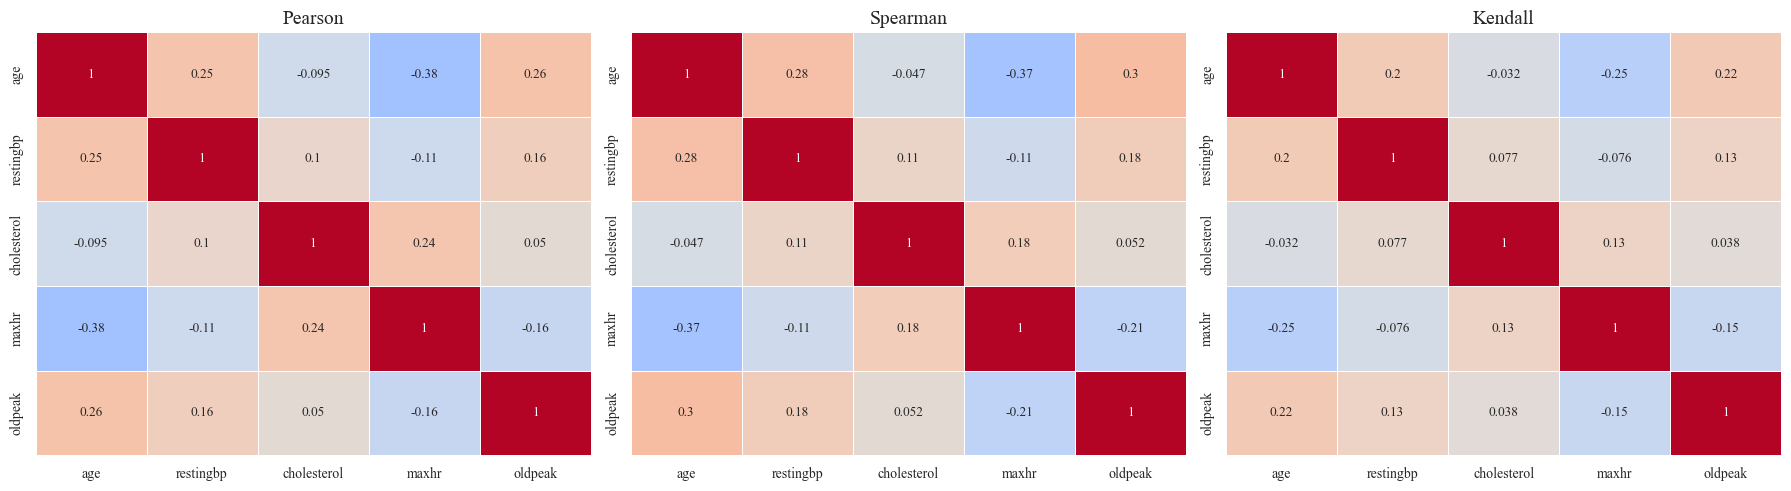

In [12]:
methods = ['pearson', 'spearman', 'kendall']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, method in zip(axes, methods):
    sns.heatmap(data[NUM_COLS].corr(method=method), cmap='coolwarm',
                annot=True, linewidth=.5, vmin=-1, vmax=1, cbar=False, ax=ax)
    ax.set_title(method.capitalize())

plt.tight_layout()
plt.show()

## Multicollinearity

Variance inflation factor, computed by regressing each feature on all the others:
`VIF = 1 / (1 - R²)`.

In [13]:
def variance_inflation(df):
    vif = {}
    for feature in df.columns:
        others = df.drop(columns=[feature])
        r_squared = LinearRegression().fit(others, df[feature]).score(others, df[feature])
        vif[feature] = 1 / (1 - r_squared)
    return pd.Series(vif, name='vif').to_frame()


variance_inflation(data[NUM_COLS])

,vif
age,1.285821
restingbp,1.099498
cholesterol,1.086453
maxhr,1.240133
oldpeak,1.096271


No multicollinearity presents in the dataset

## Ranking the features by discriminative power

Mann-Whitney because none of the numerical variables look normal, plus Cohen's d for the
size of the gap between the two groups.

In [14]:
rows = []
for col in NUM_COLS:
    healthy = data.loc[data['heartdisease'] == 0, col].dropna()
    diseased = data.loc[data['heartdisease'] == 1, col].dropna()

    _, p_value = mannwhitneyu(healthy, diseased, alternative='two-sided')
    pooled_std = np.sqrt((healthy.std() ** 2 + diseased.std() ** 2) / 2)

    rows.append({
        'feature': col,
        'mean_no_disease': healthy.mean(),
        'mean_disease': diseased.mean(),
        'difference': abs(diseased.mean() - healthy.mean()),
        'p_value': p_value,
        'effect_size': abs(diseased.mean() - healthy.mean()) / pooled_std,
        'significant': p_value < 0.05,
    })

pd.DataFrame(rows).sort_values('effect_size', ascending=False)

,feature,mean_no_disease,mean_disease,difference,p_value,effect_size,significant
4,oldpeak,0.408049,1.274213,0.866164,6.767845e-37,0.908885,True
3,maxhr,148.151220,127.655512,20.495708,1.506359e-34,0.878229,True
0,age,50.551220,55.899606,5.348387,1.805694e-18,0.588183,True
2,cholesterol,227.121951,175.940945,51.181006,2.280312e-05,0.493116,True
1,restingbp,130.180488,134.185039,4.004552,5.648075e-04,0.219545,True
